In [85]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.integrate import quad
from matplotlib.colors import TwoSlopeNorm
import matplotlib as mpl

In [86]:
def fulton_a(a, beta = -0.86,a0 = 3.6,gamma = 1.58):

    return (
        a**beta
        * (1 - np.exp(-(a / a0)**gamma))
    )

In [87]:


def fulton_weighted_average(p, a_min=0.1, a_max=100):
    numerator = quad(
        lambda a: a**(2-p) * fulton_a(a),
        a_min, a_max
    )[0]

    denominator = quad(
        fulton_a,
        a_min, a_max
    )[0]

    return numerator / denominator

In [88]:
def disc_correction(p, r_max, r_min=0, a_min=0.1, a_max=100):
    W = 2.5**(2-p) - 0.5**(2-p)

    moment = fulton_weighted_average(p, a_min, a_max)
    mean_a = fulton_weighted_average(1, a_min, a_max)

    return (
        (125 / 2)
        * W * moment
        / (mean_a * (r_max**(2-p) - r_min**(2-p)))
    )

In [89]:
disc_correction(2, 100)

ZeroDivisionError: float division by zero

In [ ]:
p=np.linspace(0.5,1.95,1000)
r_max=np.logspace(np.log10(20),np.log10(200), 100)

In [ ]:
P,R = np.meshgrid(p,r_max)

In [ ]:
C = np.empty_like(P)

for i in range(P.shape[0]):
    for j in range(P.shape[1]):
        C[i, j] = disc_correction(
            P[i, j],
            R[i, j],
            r_min=0
        )

In [ ]:
p_small=np.linspace(0.5,1.95,100)
r_max_small=np.logspace(np.log10(20),np.log10(200), 100)
P_small,R_small = np.meshgrid(p_small,r_max_small)
C_small = np.empty_like(P_small)

for i in range(P_small.shape[0]):
    for j in range(P_small.shape[1]):
        C_small[i, j] = disc_correction(
            P_small[i, j],
            R_small[i, j],
            r_min=0
        )

In [ ]:
log_C_small = np.log10(C_small)
limit = np.max(np.abs(log_C_small))

In [115]:
log_C = np.log10(C)
limit = np.max(np.abs(log_C))

In [ ]:
cm=1/2.54

In [91]:
mpl.rcdefaults()

In [92]:
# plot_style = {
#     # General font
#     "font.family": "serif",
#     "font.size": 12,
#     "mathtext.fontset": "dejavusans",


#     # Axis labels
#     "axes.labelsize": 10,
#     "axes.labelweight": "normal",

#     # Axis titles
#     "axes.titlesize": 10,
#     "axes.titleweight": "normal",

#     # Tick labels (including colorbar ticks)
#     "xtick.labelsize": 10,
#     "ytick.labelsize": 10,

#     # Tick appearance
#     "xtick.direction": "in",
#     "ytick.direction": "in",
#     "xtick.major.size": 5,
#     "ytick.major.size": 5,
#     "xtick.minor.size": 3,
#     "ytick.minor.size": 3,

#     # Legend
#     "legend.fontsize": 10,
#     "legend.title_fontsize": 10,



#     # Contour labels (see note below)
# }

# mpl.rcParams.update(plot_style)

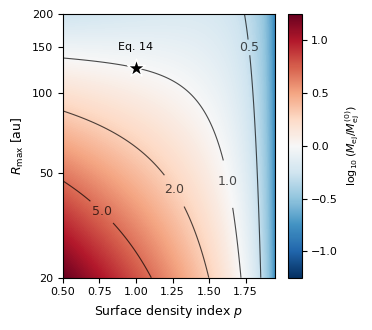

In [ ]:
fig, ax = plt.subplots(figsize=(8.7*cm, 8.7*cm))

pcm = ax.pcolormesh(
    P, R, log_C,
    cmap="RdBu_r",
    norm=TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit),
    shading="auto"
)

# Contour where correction = 1
levels = [0.5, 1, 2, 5]

contours = ax.contour(
    P, R, C,
    levels=levels,
    colors="black",
    linewidths=0.8,
    alpha=0.7
)

label_positions=[
    (1.8, 150),
    (1.7,50),
    (1.3,50),
    (0.75,30)]

labels=ax.clabel(
    contours,
    fmt={level: f"{level:.1f}" for level in levels},
    manual=label_positions,
    fontsize=9,
    inline=True
)

for label in labels:
    label.set_rotation(0)
# Fiducial model
ax.scatter(
    1, 125,
    marker="*",
    s=180,
    color="black",
    edgecolor="white",
    zorder=5,
    label="Fiducial model"
)

ax.set_xlabel(r"Surface density index $p$", fontsize=9)
ax.set_ylabel(r"$R_{\max}$ [au]",fontsize=9)
ax.set_ylim(20,200)
ax.text(1.0,150, 'Eq. 14', fontsize=8, color='black', rotation=0, ha='center', va='center')
ax.set_yscale("log")
ticks = [20, 50, 100, 150, 200]
ax.set_yticks(ticks)
ax.set_yticklabels([str(tick) for tick in ticks])
ax.tick_params(labelsize=8)
ax.yaxis.set_minor_locator(plt.NullLocator())

cbar = fig.colorbar(pcm, ax=ax)
cbar.set_label(r"$\log_{10}(M_{\rm ej}/M_{\rm ej}^{(0)})$", fontsize=8)
cbar.ax.tick_params(labelsize=8)

#plt.savefig('/Users/haydenmonk/Downloads/HPCC/Mass_Fraction/Outputs/Visualizations/mass_correction_heatmap.png', dpi=500, bbox_inches='tight', facecolor='white')